# Task 2: Real Estate Housing Price Prediction

## OLS, Ridge (L2) and Lasso (L1) Regression

**Datheon Machine Learning & Data Science Internship**

### Project goal

Predict California district median house values from demographic, housing and location features. This notebook follows a leakage-aware machine-learning workflow and compares:

- Ordinary Least Squares (OLS) using `LinearRegression`
- Ridge regression using L2 regularisation
- Lasso regression using L1 regularisation

Models are compared using **RMSE**, **MAE** and **R²** on the same held-out test set.

### Learning outcomes

By completing this notebook, you will practise data inspection, exploratory analysis, missing-value imputation, categorical encoding, feature engineering, standardisation, multicollinearity diagnostics, cross-validation, hyperparameter tuning and residual analysis.

> **Important:** The uploaded CSV is expected at `data/housing.csv` beside this notebook. If you move the notebook, keep the `data` folder alongside it or update `DATA_PATH` in the next section.


## 1. Import libraries and configure the project

We use:

- **Pandas / NumPy** for data handling and numerical operations.
- **Matplotlib / Seaborn** for static visualisations.
- **Scikit-learn** for preprocessing, regression, cross-validation and metrics.
- **Statsmodels** optionally for Variance Inflation Factor (VIF).

The notebook uses a fixed random seed so that the train/test split and results are reproducible. A test set is held back until final evaluation; model selection is performed using cross-validation on the training set only.


In [1]:
# If a required library is missing, install it in your active environment from Terminal:
# python3 -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel statsmodels plotly

from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Libraries imported successfully.")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)


Libraries imported successfully.
Pandas: 3.0.3
NumPy: 2.4.6


## 2. Load the California Housing dataset

The dataset contains California census-block-group observations. Each row describes a district, not an individual house.

The target, `median_house_value`, is expressed in US dollars. The original dataset caps some target values at **$500,001**, so predictions near this ceiling should be interpreted with care: the target is top-coded rather than an exact uncensored market price.


In [7]:
# Resolve the CSV relative to the notebook's working directory.
search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path("/Users/mac/Desktop/Internship"),
]
file_names = {"task 2-housing.csv", "task_2_housing.csv", "housing.csv"}

candidate_paths = []
for root in search_roots:
    if root.is_dir():
        candidate_paths.extend(
            path for path in root.rglob("*.csv")
            if path.name.lower() in file_names
        )

candidate_paths = list(dict.fromkeys(candidate_paths))
DATA_PATH = next((path for path in candidate_paths if path.is_file()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Housing CSV not found. Place Task_2_Housing.csv or housing.csv in the "
        "notebook folder or one of its subfolders, or set DATA_PATH to its full path."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset loaded from: {DATA_PATH.resolve()}")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())


Dataset loaded from: /Users/mac/Desktop/Internship/Task 2-Housing.csv
Rows: 20,640 | Columns: 10


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


## 3. Initial data inspection

We inspect the structure, data types, descriptive statistics, duplicate rows and missing values before making preprocessing decisions.

A missing value in `total_bedrooms` is expected in this version of the dataset. We will not delete those rows; instead, the median imputer will learn the replacement value from the training data only.


In [8]:
print("Dataset dimensions:", df.shape)
print("\nColumn data types:")
display(df.dtypes.to_frame("data_type"))

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nMissing values by column:")
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_summary)

print("\nDuplicate rows:", df.duplicated().sum())


Dataset dimensions: (20640, 10)

Column data types:


,data_type
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,"20,640.000",NaN,NaN,NaN,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,"20,640.000",NaN,NaN,NaN,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_median_age,"20,640.000",NaN,NaN,NaN,28.639,12.586,1.000,18.000,29.000,37.000,52.000
total_rooms,"20,640.000",NaN,NaN,NaN,"2,635.763","2,181.615",2.000,"1,447.750","2,127.000","3,148.000","39,320.000"
total_bedrooms,"20,433.000",NaN,NaN,NaN,537.871,421.385,1.000,296.000,435.000,647.000,"6,445.000"
population,"20,640.000",NaN,NaN,NaN,"1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000"
households,"20,640.000",NaN,NaN,NaN,499.540,382.330,1.000,280.000,409.000,605.000,"6,082.000"
median_income,"20,640.000",NaN,NaN,NaN,3.871,1.900,0.500,2.563,3.535,4.743,15.000
median_house_value,"20,640.000",NaN,NaN,NaN,"206,855.817","115,395.616","14,999.000","119,600.000","179,700.000","264,725.000","500,001.000"
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,missing_count,missing_percent
total_bedrooms,207,1.000
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000



Duplicate rows: 0


## 4. Complete data cleaning and missing-value treatment

This section performs a documented quality check before exploratory analysis and modelling. We preserve the original loaded data in `df_raw` so that cleaning decisions remain auditable.

Cleaning steps:

1. Standardise column names and remove leading/trailing spaces from text categories.
2. Remove exact duplicate rows.
3. Convert known invalid numeric values (for example, impossible negative counts or out-of-range coordinates) to missing values rather than silently keeping them.
4. Check target availability. Rows without a target cannot be used for supervised training, so they are removed.
5. Report missingness after rule-based cleaning.
6. Impute predictor missing values inside the training-only preprocessing pipeline in Section 9. Numeric predictors use the median; categorical predictors use the most frequent category.

**Important:** We do not automatically delete statistical outliers. Large populations, room counts or house values can be legitimate district characteristics. Outliers are investigated in EDA and retained unless they are demonstrably invalid.


In [11]:

# Keep an untouched copy for comparison and audit.
df_raw = df.copy()

# 4.1 Standardise column names and text categories.
df.columns = (
    df.columns.astype(str)
      .str.strip()
      .str.lower()
      .str.replace(r"[^a-z0-9]+", "_", regex=True)
      .str.strip("_")
)

# Identify categorical columns, including newer Pandas string dtype.
categorical_cols = df.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

for column in categorical_cols:
    # Remove accidental whitespace; preserve genuinely missing entries.
    df[column] = df[column].map(
        lambda value: value.strip() if isinstance(value, str) else value
    )

    # Convert empty strings to missing values.
    df[column] = df[column].replace("", np.nan)

print("Column names after standardisation:")
print(df.columns.tolist())

print("\nCategorical columns:")
print(categorical_cols)


Column names after standardisation:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Categorical columns:
['ocean_proximity']


In [12]:
# 4.2 Remove exact duplicate observations.
duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
duplicates_removed = duplicates_before

print(f"Exact duplicate rows found: {duplicates_before:,}")
print(f"Exact duplicate rows removed: {duplicates_removed:,}")
print("Shape after duplicate removal:", df.shape)


Exact duplicate rows found: 0
Exact duplicate rows removed: 0
Shape after duplicate removal: (20640, 10)


In [13]:
# 4.3 Convert invalid numeric values to NaN.
# These rules are domain checks, not statistical outlier filters.
numeric_cols_for_cleaning = df.select_dtypes(include=np.number).columns.tolist()

# Replace positive/negative infinity with missing values.
df[numeric_cols_for_cleaning] = df[numeric_cols_for_cleaning].replace(
    [np.inf, -np.inf], np.nan
)

invalid_value_counts = {}

# Count variables and household/population measures cannot be negative.
non_negative_columns = [
    "total_rooms", "total_bedrooms", "population", "households",
    "median_income", "housing_median_age", "median_house_value"
]
for column in non_negative_columns:
    if column in df.columns:
        invalid_mask = df[column] < 0
        invalid_value_counts[column] = int(invalid_mask.sum())
        df.loc[invalid_mask, column] = np.nan

# California geographic coordinates should fall within valid broad bounds.
if "longitude" in df.columns:
    invalid_mask = ~df["longitude"].between(-125, -113)
    invalid_value_counts["longitude_out_of_range"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "longitude"] = np.nan

if "latitude" in df.columns:
    invalid_mask = ~df["latitude"].between(32, 43)
    invalid_value_counts["latitude_out_of_range"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "latitude"] = np.nan

# A district's bedrooms should not exceed its total rooms.
if {"total_bedrooms", "total_rooms"}.issubset(df.columns):
    invalid_mask = (
        df["total_bedrooms"].notna()
        & df["total_rooms"].notna()
        & (df["total_bedrooms"] > df["total_rooms"])
    )
    invalid_value_counts["bedrooms_greater_than_rooms"] = int(invalid_mask.sum())
    df.loc[invalid_mask, "total_bedrooms"] = np.nan

print("Invalid values converted to missing values:")
display(pd.Series(invalid_value_counts, name="count").to_frame())


Invalid values converted to missing values:


,count
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
housing_median_age,0
median_house_value,0
longitude_out_of_range,0
latitude_out_of_range,0
bedrooms_greater_than_rooms,0


In [14]:
# 4.4 Validate required columns and remove rows with missing target values.
required_columns = {
    "longitude", "latitude", "housing_median_age", "total_rooms",
    "total_bedrooms", "population", "households", "median_income",
    "median_house_value", "ocean_proximity"
}
missing_required_columns = required_columns.difference(df.columns)

if missing_required_columns:
    raise ValueError(
        f"Dataset is missing required columns: {sorted(missing_required_columns)}"
    )

target_missing_before = int(df["median_house_value"].isna().sum())
df = df.dropna(subset=["median_house_value"]).reset_index(drop=True)

print(f"Rows removed because target was missing: {target_missing_before:,}")
print("Shape after target validation:", df.shape)


Rows removed because target was missing: 0
Shape after target validation: (20640, 10)


In [15]:
# 4.5 Produce a complete data-quality and missingness report.
cleaning_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values(["missing_count", "missing_percent"], ascending=False)

print("Data quality report after rule-based cleaning:")
display(cleaning_report)

print("Remaining duplicate rows:", df.duplicated().sum())
print("Rows retained:", len(df))
print("Columns retained:", df.shape[1])

# Save the audit report so cleaning decisions are part of the deliverables.
CLEANING_OUTPUT_DIR = Path("outputs/model_results")
CLEANING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cleaning_report.to_csv(CLEANING_OUTPUT_DIR / "data_cleaning_report.csv")


Data quality report after rule-based cleaning:


,data_type,missing_count,missing_percent,unique_values
total_bedrooms,float64,207,1.000,1923
longitude,float64,0,0.000,844
latitude,float64,0,0.000,862
housing_median_age,float64,0,0.000,52
total_rooms,float64,0,0.000,5926
population,float64,0,0.000,3888
households,float64,0,0.000,1815
median_income,float64,0,0.000,12928
median_house_value,float64,0,0.000,3842
ocean_proximity,str,0,0.000,5


Remaining duplicate rows: 0
Rows retained: 20640
Columns retained: 10


### How missing values are handled

We intentionally do **not** fill predictor missing values across the entire dataset at this point. Doing so before the train/test split would allow information from the test set to influence the imputation values (data leakage).

Instead, the modelling pipeline later performs:

- **Numeric predictors:** median imputation learned from each training fold.
- **Categorical predictors:** most-frequent imputation learned from each training fold.
- **Engineered ratios:** any undefined values caused by zero denominators are also treated as missing and median-imputed by the numeric pipeline.
- **Target:** rows with missing target values are removed because a supervised model cannot learn from an unknown outcome.

This approach cleans the data while keeping the evaluation honest.


## 5. Define the target and inspect the target distribution

`median_house_value` is the continuous outcome we want to predict. We inspect its distribution and key percentiles to understand skewness and the upper-value cap.


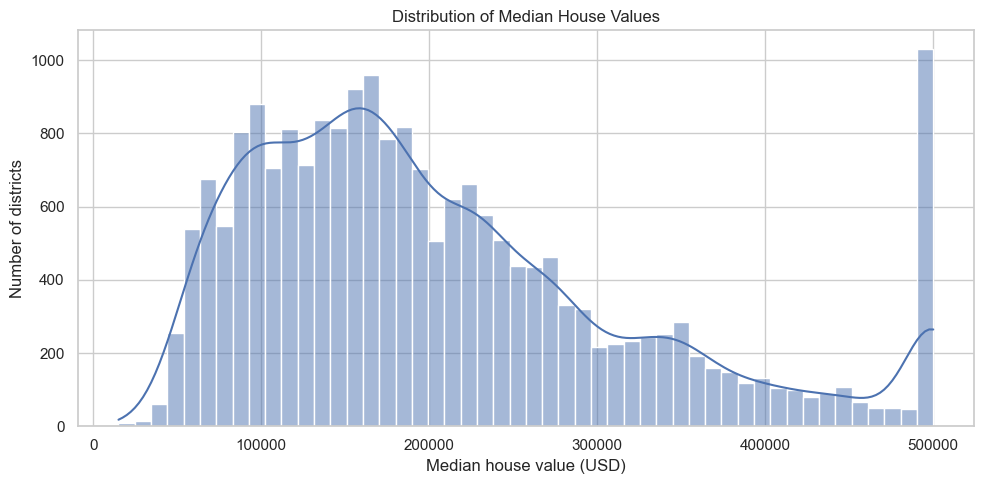

,median_house_value
count,"20,640.000"
mean,"206,855.817"
std,"115,395.616"
min,"14,999.000"
25%,"119,600.000"
50%,"179,700.000"
75%,"264,725.000"
90%,"376,600.000"
95%,"489,810.000"
99%,"500,001.000"


Share of target values at $500,001: 4.68%


In [16]:
TARGET = "median_house_value"

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' was not found.")

plt.figure(figsize=(10, 5))
sns.histplot(df[TARGET], bins=50, kde=True)
plt.title("Distribution of Median House Values")
plt.xlabel("Median house value (USD)")
plt.ylabel("Number of districts")
plt.tight_layout()
plt.show()

display(df[TARGET].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).to_frame())
print("Share of target values at $500,001:",
      f"{(df[TARGET] == 500001).mean() * 100:.2f}%")


## 6. Exploratory data analysis (EDA)

### 5.1 Numeric feature distributions

Histograms reveal skewness and unusual ranges. Several count variables (rooms, bedrooms, population and households) are typically strongly right-skewed.


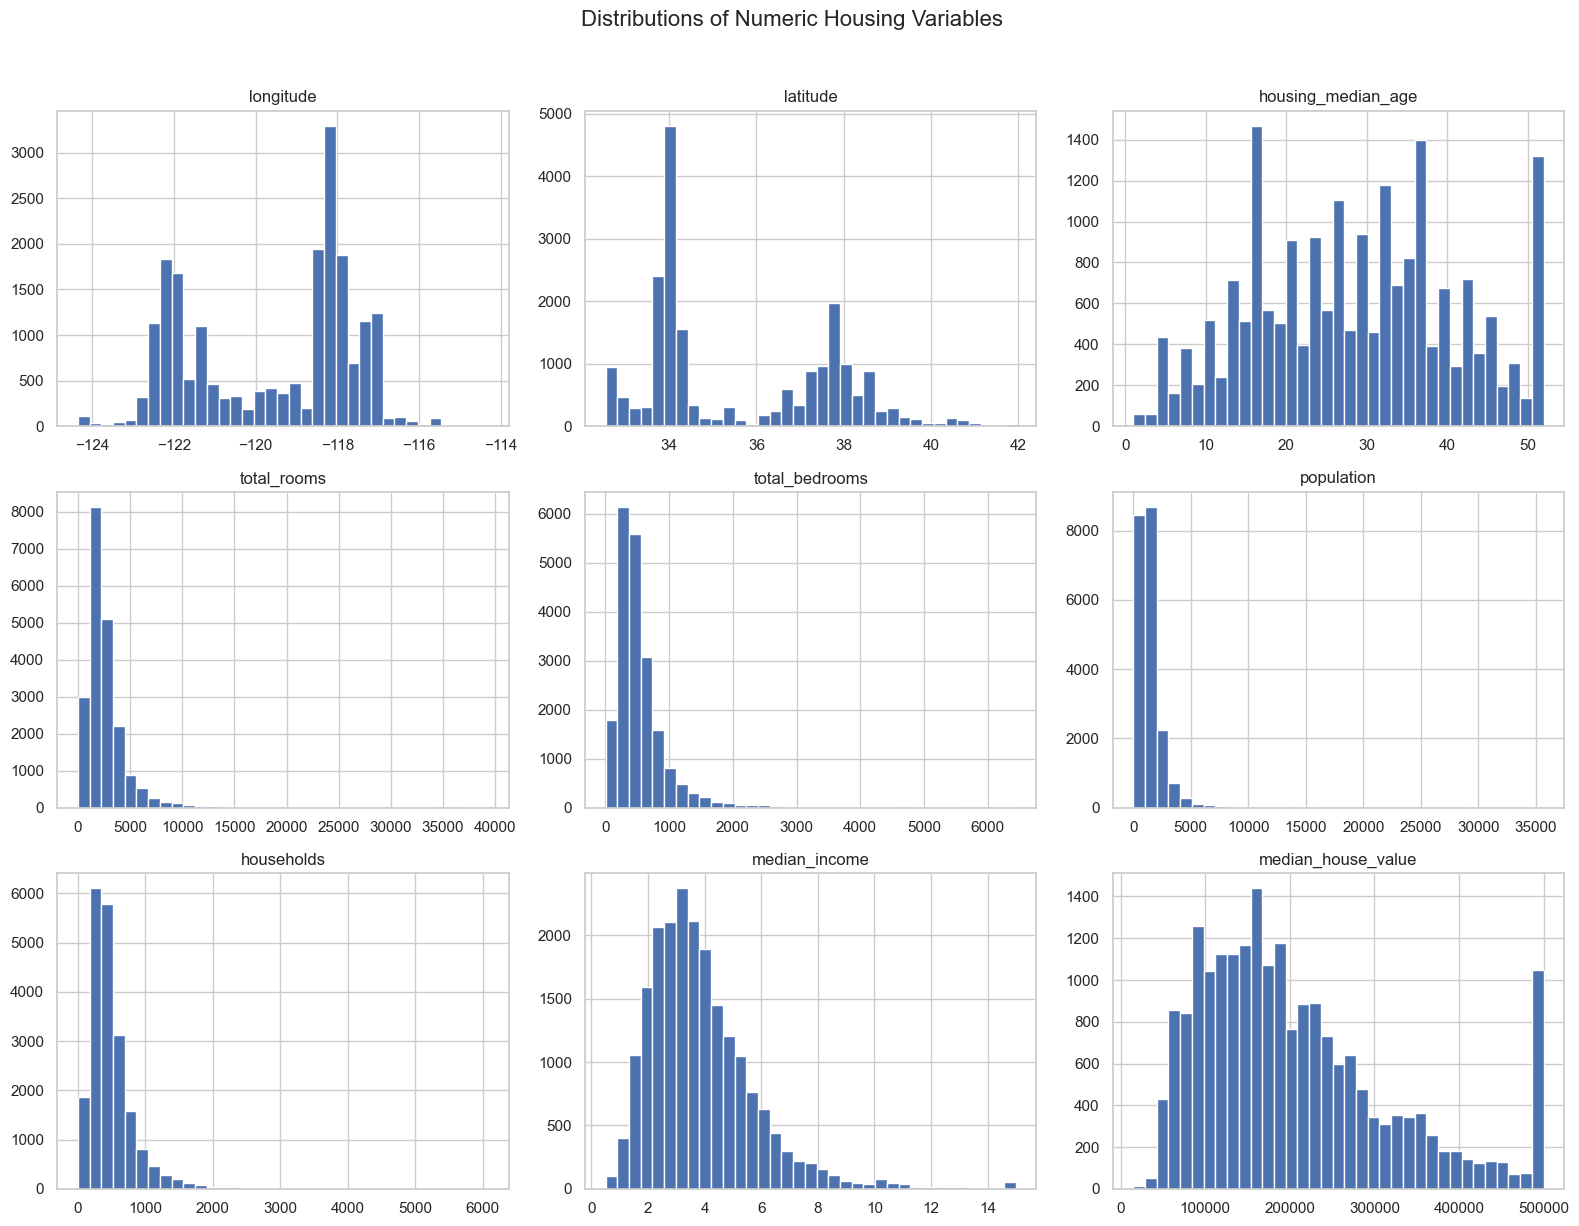

In [17]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_columns].hist(figsize=(16, 12), bins=35, edgecolor="white")
plt.suptitle("Distributions of Numeric Housing Variables", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()


### 5.2 Boxplots for potential outliers

Boxplots help identify extreme observations. Outliers are not automatically removed: unusually large districts can be valid observations. We will retain them unless a data-quality reason justifies removal.


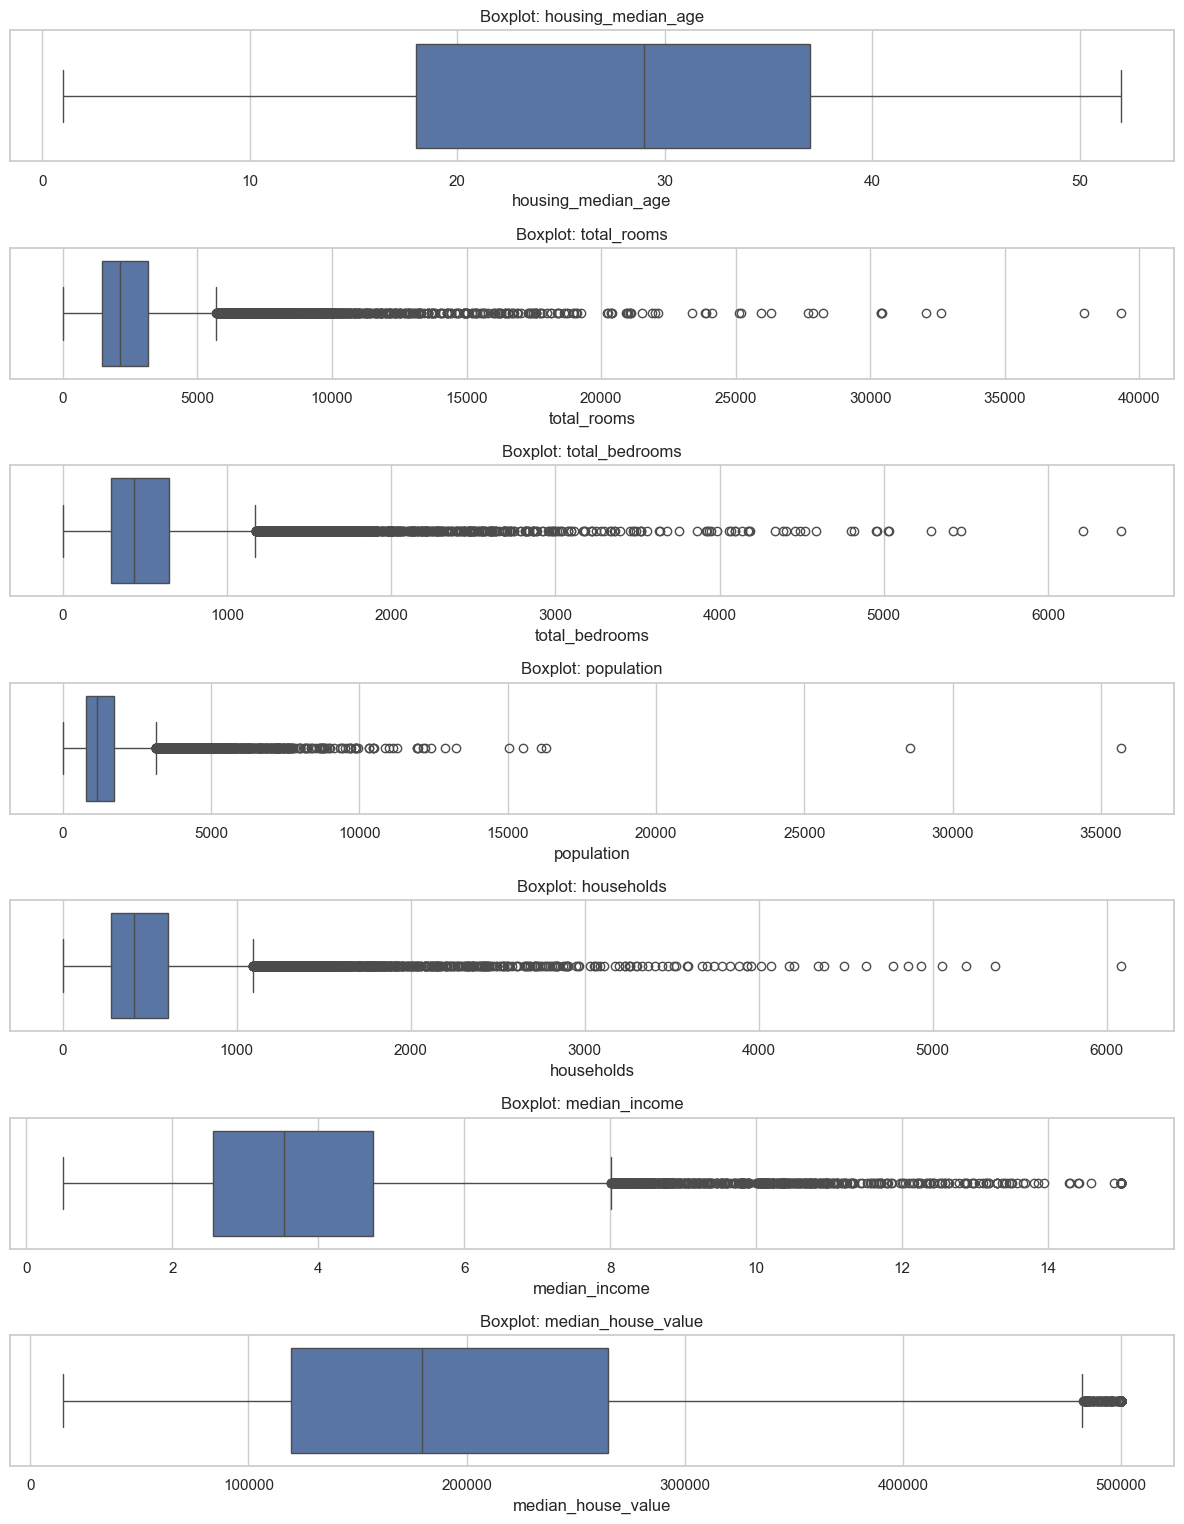

In [18]:
box_columns = [
    "housing_median_age", "total_rooms", "total_bedrooms",
    "population", "households", "median_income", TARGET
]
available_box_columns = [col for col in box_columns if col in df.columns]

fig, axes = plt.subplots(len(available_box_columns), 1,
                         figsize=(12, 2.2 * len(available_box_columns)))
if len(available_box_columns) == 1:
    axes = [axes]

for ax, col in zip(axes, available_box_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()


### 5.3 Geographic distribution

Longitude and latitude allow a simple geographic view of the observations. The colour represents median house value; this is exploratory and does not imply that location alone causes the observed prices.


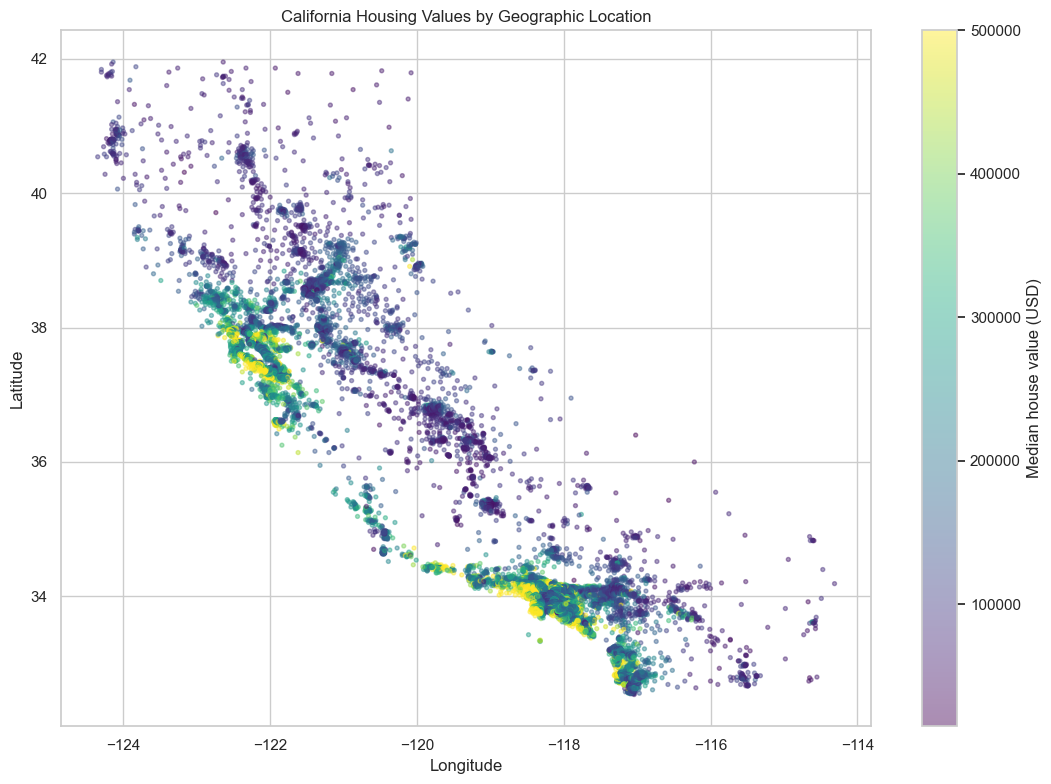

In [19]:
plt.figure(figsize=(11, 8))
scatter = plt.scatter(
    df["longitude"], df["latitude"],
    c=df[TARGET], cmap="viridis", s=8, alpha=0.45
)
plt.colorbar(scatter, label="Median house value (USD)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("California Housing Values by Geographic Location")
plt.tight_layout()
plt.show()


### 5.4 Correlation heatmap

Pearson correlation measures linear association between numeric variables. Values close to +1 or -1 indicate stronger linear association; values near 0 indicate weaker linear association.

Correlation is not proof of causation. We use this heatmap as an initial screen for potential multicollinearity and relationships with the target.


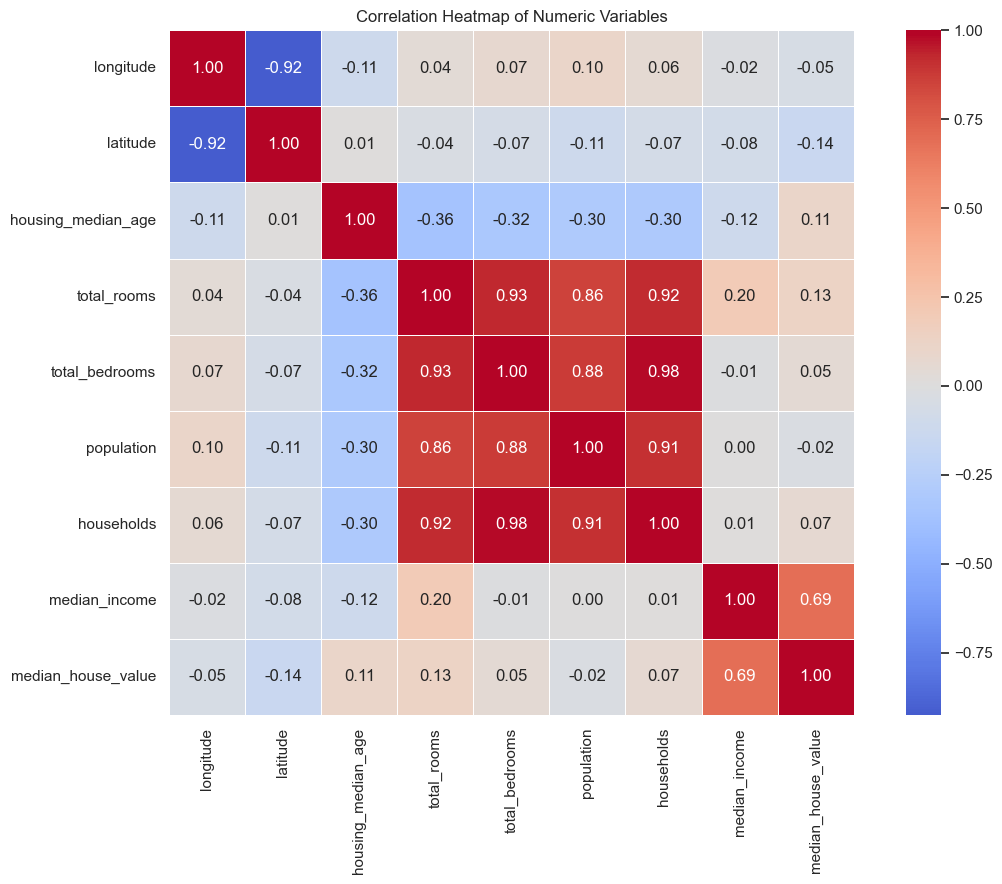

Numeric features ranked by absolute correlation with the target:


,correlation_with_target
median_income,0.688
latitude,-0.144
total_rooms,0.134
housing_median_age,0.106
households,0.066
total_bedrooms,0.050
longitude,-0.046
population,-0.025


In [20]:
correlation_matrix = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix, annot=True, fmt=".2f",
    cmap="coolwarm", center=0, square=True,
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

target_correlations = correlation_matrix[TARGET].drop(TARGET).sort_values(
    key=lambda values: values.abs(), ascending=False
)
print("Numeric features ranked by absolute correlation with the target:")
display(target_correlations.to_frame("correlation_with_target"))


### 5.5 Categorical feature

`ocean_proximity` is categorical. We inspect its categories and the median target value within each group. The model will later encode this column using one-hot encoding rather than assigning arbitrary numeric ranks.


,district_count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


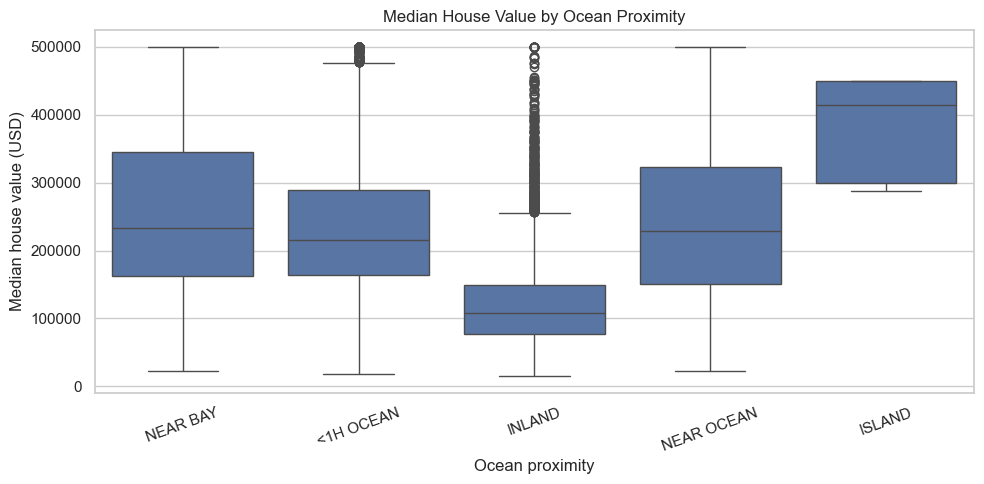

,count,mean,median
ocean_proximity,,,
ISLAND,5,"380,440.000","414,700.000"
NEAR BAY,2290,"259,212.312","233,800.000"
NEAR OCEAN,2658,"249,433.977","229,450.000"
<1H OCEAN,9136,"240,084.285","214,850.000"
INLAND,6551,"124,805.392","108,500.000"


In [21]:
display(df["ocean_proximity"].value_counts(dropna=False).to_frame("district_count"))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="ocean_proximity", y=TARGET)
plt.title("Median House Value by Ocean Proximity")
plt.xlabel("Ocean proximity")
plt.ylabel("Median house value (USD)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

display(
    df.groupby("ocean_proximity", dropna=False)[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("median", ascending=False)
)


## 7. Train/test split

We separate the target from the predictors and create a held-out test set. The test set is not used to fit imputers, scalers, encoders or tune alpha values.

A 80/20 split is used. We use the same split for all models to make the comparison fair.


In [22]:
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)


Training predictors: (16512, 9)
Test predictors: (4128, 9)
Training target: (16512,)
Test target: (4128,)


## 8. Feature engineering

We create interpretable ratio and interaction features:

- `rooms_per_household`: average rooms per household.
- `bedrooms_per_room`: proportion of rooms that are bedrooms.
- `population_per_household`: average population per household.
- `income_x_rooms_per_household`: an interaction between median income and rooms per household.
- `latitude_x_longitude`: a simple geographic interaction.

Ratios are calculated safely to avoid division by zero. These transformations are deterministic and do not learn from the target. They are placed inside the modelling pipeline so the same transformations are applied consistently to training and test data.


In [23]:
def add_engineered_features(data):
    """Return a copy of the input DataFrame with additional engineered features."""
    data = data.copy()

    # Safe division: zero denominators become NaN and are imputed downstream.
    data["rooms_per_household"] = (
        data["total_rooms"] / data["households"].replace(0, np.nan)
    )
    data["bedrooms_per_room"] = (
        data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
    )
    data["population_per_household"] = (
        data["population"] / data["households"].replace(0, np.nan)
    )

    # Interaction features can represent combined effects.
    data["income_x_rooms_per_household"] = (
        data["median_income"] * data["rooms_per_household"]
    )
    data["latitude_x_longitude"] = data["latitude"] * data["longitude"]

    return data

# Preview the engineered data for learning and inspection.
X_train_engineered_preview = add_engineered_features(X_train)
new_features = [
    "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_x_rooms_per_household",
    "latitude_x_longitude"
]
display(X_train_engineered_preview[new_features].describe().T)


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,"16,512.000",5.435,2.387,0.889,4.452,5.236,6.061,141.909
bedrooms_per_room,"16,512.000",0.213,0.058,0.100,0.175,0.203,0.240,1.000
population_per_household,"16,512.000",3.097,11.579,0.692,2.429,2.817,3.280,"1,243.333"
income_x_rooms_per_household,"16,512.000",22.620,17.555,0.857,11.709,18.098,28.014,333.336
latitude_x_longitude,"16,512.000","-4,266.251",324.080,"-5,207.673","-4,601.572","-4,062.149","-4,004.363","-3,757.240"


## 9. Multicollinearity diagnostics

Multicollinearity occurs when predictors contain overlapping information. It can make ordinary least-squares coefficients unstable and difficult to interpret. Ridge and Lasso are useful regularisation approaches, although they do not make every correlated feature problem disappear.

We first inspect the correlation matrix of engineered numeric training features. We also calculate Variance Inflation Factor (VIF) when `statsmodels` is installed. VIF is calculated on the training predictors only, after median imputation for this diagnostic. Very large VIF values can indicate redundancy; interpret them alongside domain knowledge and the correlation heatmap.


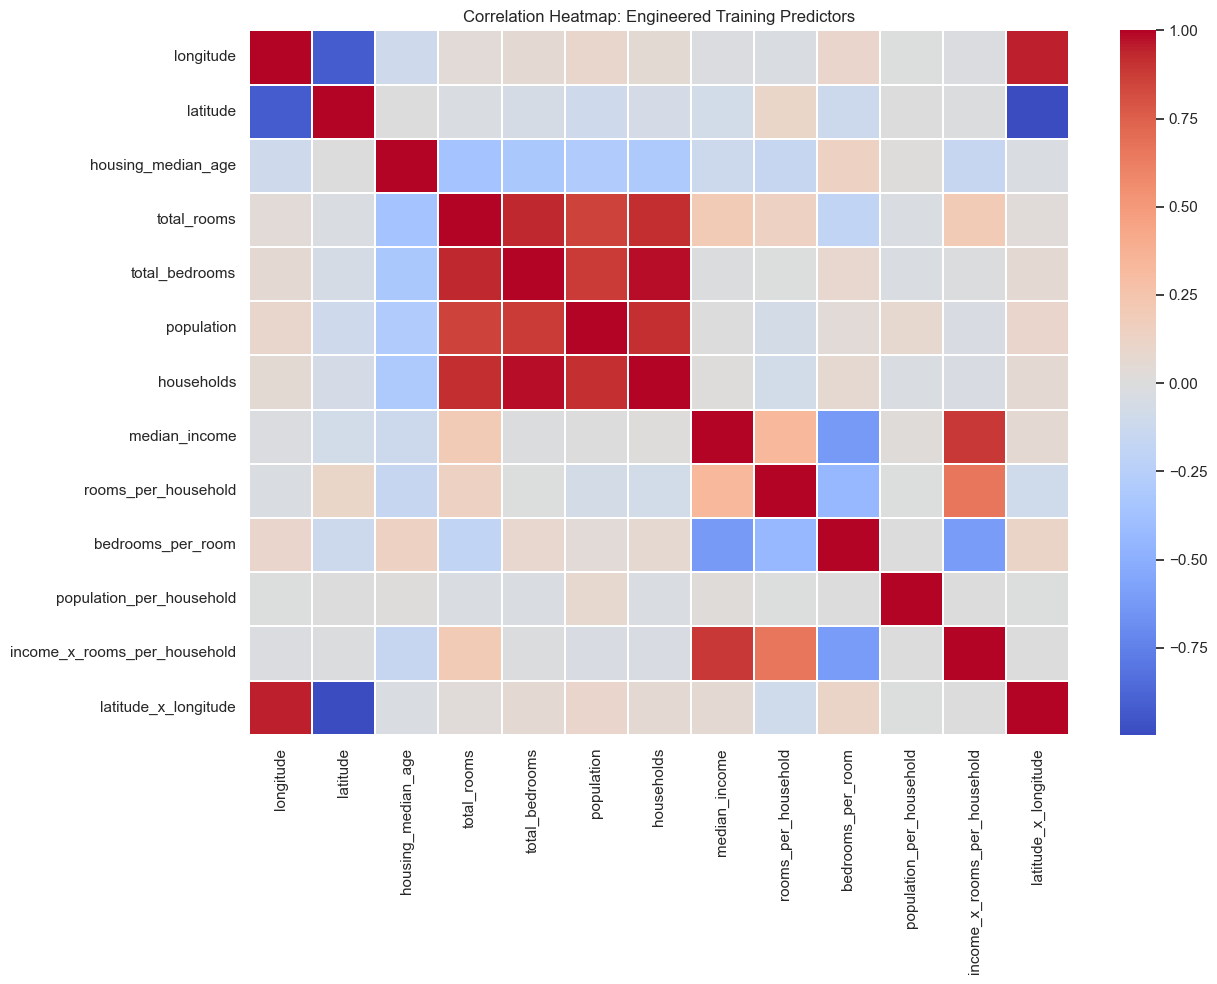

,feature,VIF
12,latitude_x_longitude,"13,243.048"
1,latitude,"8,339.793"
0,longitude,649.174
4,total_bedrooms,49.938
6,households,47.028
3,total_rooms,18.840
11,income_x_rooms_per_household,17.801
7,median_income,13.700
5,population,6.905
8,rooms_per_household,4.510


In [24]:
X_train_engineered = add_engineered_features(X_train)
numeric_engineered_columns = X_train_engineered.select_dtypes(include=np.number).columns.tolist()

# Median-impute only for this diagnostic calculation.
diagnostic_numeric = X_train_engineered[numeric_engineered_columns].copy()
diagnostic_numeric = diagnostic_numeric.replace([np.inf, -np.inf], np.nan)
diagnostic_numeric = diagnostic_numeric.fillna(diagnostic_numeric.median())

plt.figure(figsize=(13, 10))
sns.heatmap(
    diagnostic_numeric.corr(), cmap="coolwarm", center=0,
    annot=False, linewidths=0.25
)
plt.title("Correlation Heatmap: Engineered Training Predictors")
plt.tight_layout()
plt.show()

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor

    # Remove constant columns before VIF calculation.
    vif_input = diagnostic_numeric.loc[:, diagnostic_numeric.nunique() > 1].copy()
    vif_values = []
    for index, column in enumerate(vif_input.columns):
        vif_values.append(variance_inflation_factor(vif_input.values, index))

    vif_table = pd.DataFrame({
        "feature": vif_input.columns,
        "VIF": vif_values
    }).sort_values("VIF", ascending=False)
    display(vif_table)
except ImportError:
    print("statsmodels is not installed; skipping VIF. Install with:")
    print("python3 -m pip install statsmodels")
except Exception as error:
    print("VIF calculation could not be completed:", error)
    print("Use the correlation heatmap as the multicollinearity diagnostic.")


## 10. Build the preprocessing pipeline

A `ColumnTransformer` applies different preprocessing to numeric and categorical columns:

**Numeric pipeline**

1. Replace missing values with the training median.
2. Standardise features using `StandardScaler`.

**Categorical pipeline**

1. Replace missing values with the most frequent category.
2. One-hot encode categories.

Standardisation is especially important for Ridge and Lasso because their penalty is sensitive to coefficient scale. We keep preprocessing inside the scikit-learn `Pipeline`, ensuring that each cross-validation fold learns its own imputation, scaling and encoding parameters.

The helper below supports both newer and older scikit-learn versions (`sparse_output` versus `sparse`).


In [25]:
# Feature engineering step; feature names are preserved where supported.
feature_engineering = FunctionTransformer(
    add_engineered_features,
    validate=False
)

numeric_features = numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
engineered_numeric_features = numeric_features + new_features
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Support both current and older scikit-learn releases.
try:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
except TypeError:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", one_hot_encoder)
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, engineered_numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features including engineered features:", len(engineered_numeric_features))
print("Categorical features:", categorical_features)


Numeric features including engineered features: 13
Categorical features: ['ocean_proximity']


## 11. Define OLS, Ridge and Lasso models

OLS provides a baseline with no coefficient penalty. Ridge adds an L2 penalty that shrinks coefficients towards zero. Lasso adds an L1 penalty and can set some coefficients exactly to zero.

We use the same feature engineering and preprocessing steps for all three algorithms.


In [26]:
def make_model_pipeline(regressor):
    return Pipeline(steps=[
        ("feature_engineering", feature_engineering),
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

ols_model = make_model_pipeline(LinearRegression())
ridge_pipeline = make_model_pipeline(Ridge())
lasso_pipeline = make_model_pipeline(Lasso(max_iter=20000, tol=1e-4))

print("OLS, Ridge and Lasso pipelines are ready.")


OLS, Ridge and Lasso pipelines are ready.


## 12. Fit the OLS baseline

We fit OLS on the training data and calculate its test metrics. This establishes a baseline against which tuned Ridge and Lasso models can be compared.


In [27]:
ols_model.fit(X_train, y_train)
ols_predictions = ols_model.predict(X_test)

def regression_metrics(y_true, y_pred):
    """Return commonly used regression metrics."""
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

ols_metrics = regression_metrics(y_test, ols_predictions)
display(pd.DataFrame([ols_metrics], index=["OLS"]))


,RMSE,MAE,R2
OLS,"68,598.398","49,442.689",0.641


## 13. Tune Ridge and Lasso using GridSearchCV

`alpha` controls the strength of regularisation. A larger alpha means a stronger penalty.

We search a logarithmic grid of alpha values. Five-fold cross-validation is performed on the training set, using negative RMSE as the scoring metric. GridSearchCV maximises the score, so the negative sign is used because lower RMSE is better.

The held-out test set is not used during tuning.


In [30]:

from sklearn.compose import TransformedTargetRegressor

# Increase Lasso's iteration limit.
lasso_pipeline.set_params(
    regressor__max_iter=100000,
    regressor__tol=1e-4
)

# Standardise the target during training.
# Predictions are automatically converted back to dollar values.
ridge_model = TransformedTargetRegressor(
    regressor=ridge_pipeline,
    transformer=StandardScaler()
)

lasso_model = TransformedTargetRegressor(
    regressor=lasso_pipeline,
    transformer=StandardScaler()
)

# Search a wider range of regularisation strengths.
alpha_grid = np.logspace(-4, 2, 13)

cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Ridge hyperparameter tuning.
ridge_search = GridSearchCV(
    estimator=ridge_model,
    param_grid={"regressor__regressor__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

# Lasso hyperparameter tuning.
lasso_search = GridSearchCV(
    estimator=lasso_model,
    param_grid={"regressor__regressor__alpha": alpha_grid},
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

print("Tuning Ridge...")
ridge_search.fit(X_train, y_train)

print("Tuning Lasso...")
lasso_search.fit(X_train, y_train)

print("\nBest Ridge alpha:",
      ridge_search.best_params_["regressor__regressor__alpha"])

print("Best Ridge CV RMSE:",
      -ridge_search.best_score_)

print("\nBest Lasso alpha:",
      lasso_search.best_params_["regressor__regressor__alpha"])

print("Best Lasso CV RMSE:",
      -lasso_search.best_score_)


Tuning Ridge...
Tuning Lasso...

Best Ridge alpha: 0.0001
Best Ridge CV RMSE: 67534.4164998222

Best Lasso alpha: 0.0001
Best Lasso CV RMSE: 67606.95015324287


## 14. Evaluate all models on the held-out test set

We evaluate the fitted OLS baseline and the best Ridge and Lasso estimators on exactly the same test observations. This gives a fair comparison.

Metric interpretation:

- **RMSE:** typical error magnitude with extra sensitivity to large errors; measured in dollars.
- **MAE:** average absolute prediction error; measured in dollars.
- **R²:** proportion of test-target variance explained by the model. Higher is generally better; it can be negative if the model performs worse than predicting the test mean.


In [31]:
best_ridge = ridge_search.best_estimator_
best_lasso = lasso_search.best_estimator_

predictions = {
    "OLS": ols_predictions,
    "Ridge": best_ridge.predict(X_test),
    "Lasso": best_lasso.predict(X_test)
}

metrics_table = pd.DataFrame({
    model_name: regression_metrics(y_test, model_predictions)
    for model_name, model_predictions in predictions.items()
}).T

metrics_table = metrics_table.sort_values("RMSE")
display(metrics_table.style.format({
    "RMSE": "${:,.2f}",
    "MAE": "${:,.2f}",
    "R2": "{:.4f}"
}))

best_model_name = metrics_table.index[0]
print(f"Best model by test RMSE: {best_model_name}")


,RMSE,MAE,R2
OLS,"$68,598.40","$49,442.69",0.6409
Ridge,"$68,598.41","$49,442.70",0.6409
Lasso,"$68,736.68","$49,546.47",0.6394


Best model by test RMSE: OLS


## 15. Compare cross-validation results across alpha values

These plots show how the average cross-validation RMSE changes with alpha for Ridge and Lasso. The selected alpha is the value with the lowest cross-validation RMSE in the tested grid.


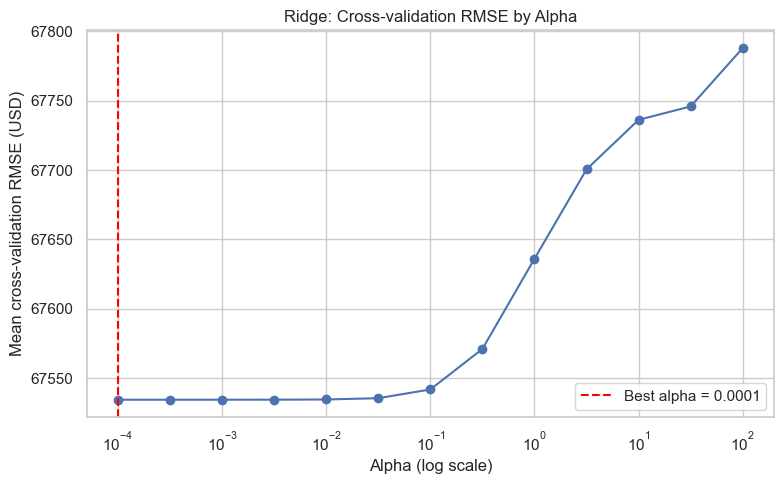

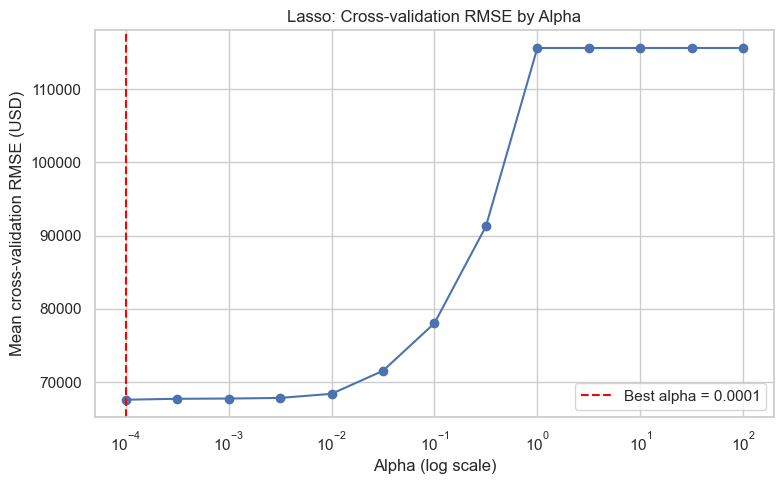

In [33]:
def plot_grid_search(search, model_label):
    results = pd.DataFrame(search.cv_results_)
    results["alpha"] = results["param_regressor__regressor__alpha"].astype(float)
    results["mean_cv_rmse"] = -results["mean_test_score"]

    plt.figure(figsize=(8, 5))
    plt.semilogx(results["alpha"], results["mean_cv_rmse"], marker="o")
    plt.axvline(
        search.best_params_["regressor__regressor__alpha"],
        color="red", linestyle="--",
        label=f"Best alpha = {search.best_params_['regressor__regressor__alpha']:.4g}"
    )
    plt.xlabel("Alpha (log scale)")
    plt.ylabel("Mean cross-validation RMSE (USD)")
    plt.title(f"{model_label}: Cross-validation RMSE by Alpha")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_grid_search(ridge_search, "Ridge")
plot_grid_search(lasso_search, "Lasso")


## 16. Actual versus predicted values

A strong model should place predictions reasonably close to the 45-degree reference line. Systematic deviations can indicate bias, nonlinear patterns or difficulty predicting particular price ranges.


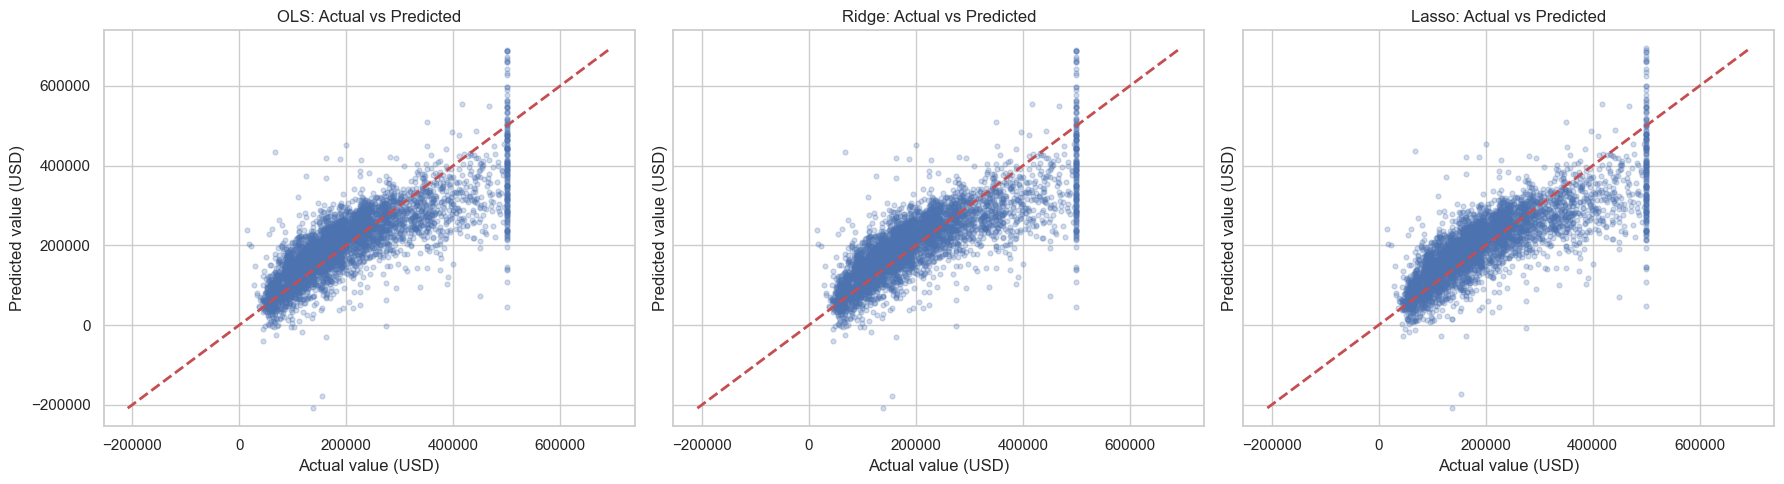

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

for ax, (model_name, model_predictions) in zip(axes, predictions.items()):
    ax.scatter(y_test, model_predictions, alpha=0.25, s=12)
    lower = min(y_test.min(), model_predictions.min())
    upper = max(y_test.max(), model_predictions.max())
    ax.plot([lower, upper], [lower, upper], "r--", linewidth=2)
    ax.set_title(f"{model_name}: Actual vs Predicted")
    ax.set_xlabel("Actual value (USD)")
    ax.set_ylabel("Predicted value (USD)")

plt.tight_layout()
plt.show()


## 17. Residual analysis

A residual is the observed target minus the model prediction:

**Residual = Actual value − Predicted value**

- Positive residual: the model underpredicted the house value.
- Negative residual: the model overpredicted the house value.
- Residuals randomly scattered around zero are generally desirable.
- A funnel shape can indicate non-constant error variance (heteroscedasticity).
- Curvature can indicate a missing nonlinear relationship.

We inspect residuals against fitted values and their distributions for all three models.


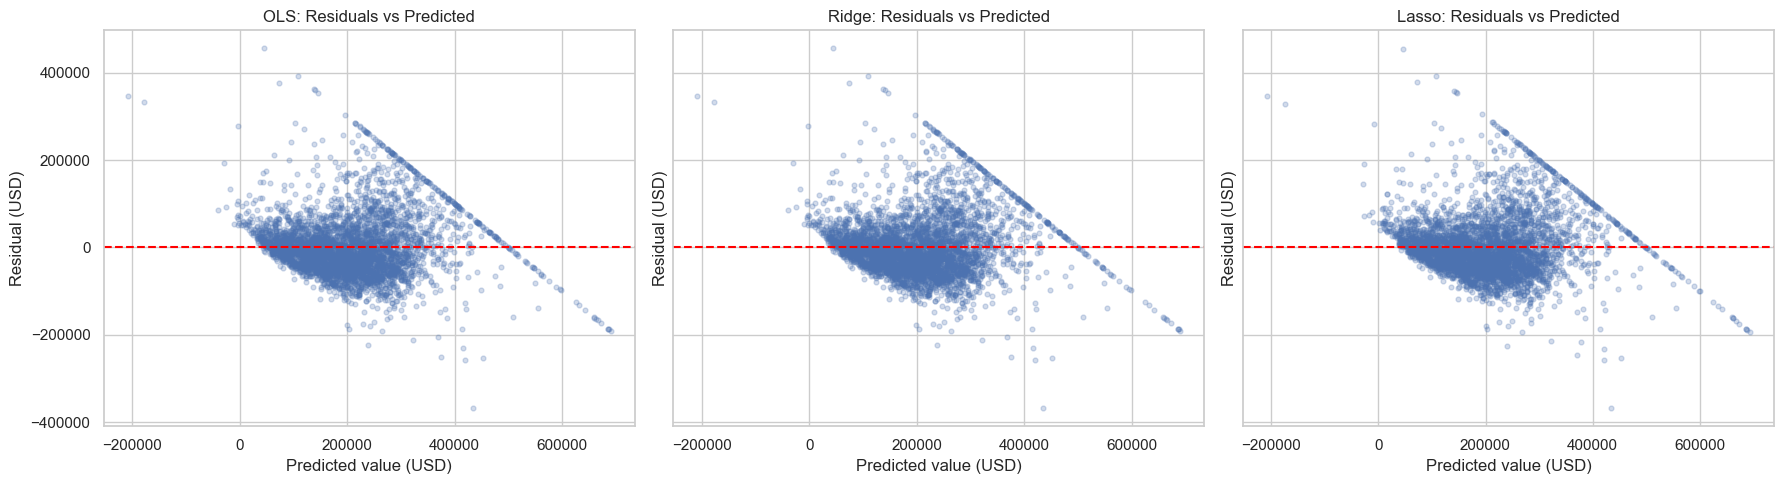

In [35]:
residuals = {
    model_name: y_test.to_numpy() - model_predictions
    for model_name, model_predictions in predictions.items()
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (model_name, model_predictions) in zip(axes, predictions.items()):
    ax.scatter(model_predictions, residuals[model_name], alpha=0.25, s=12)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{model_name}: Residuals vs Predicted")
    ax.set_xlabel("Predicted value (USD)")
    ax.set_ylabel("Residual (USD)")

plt.tight_layout()
plt.show()


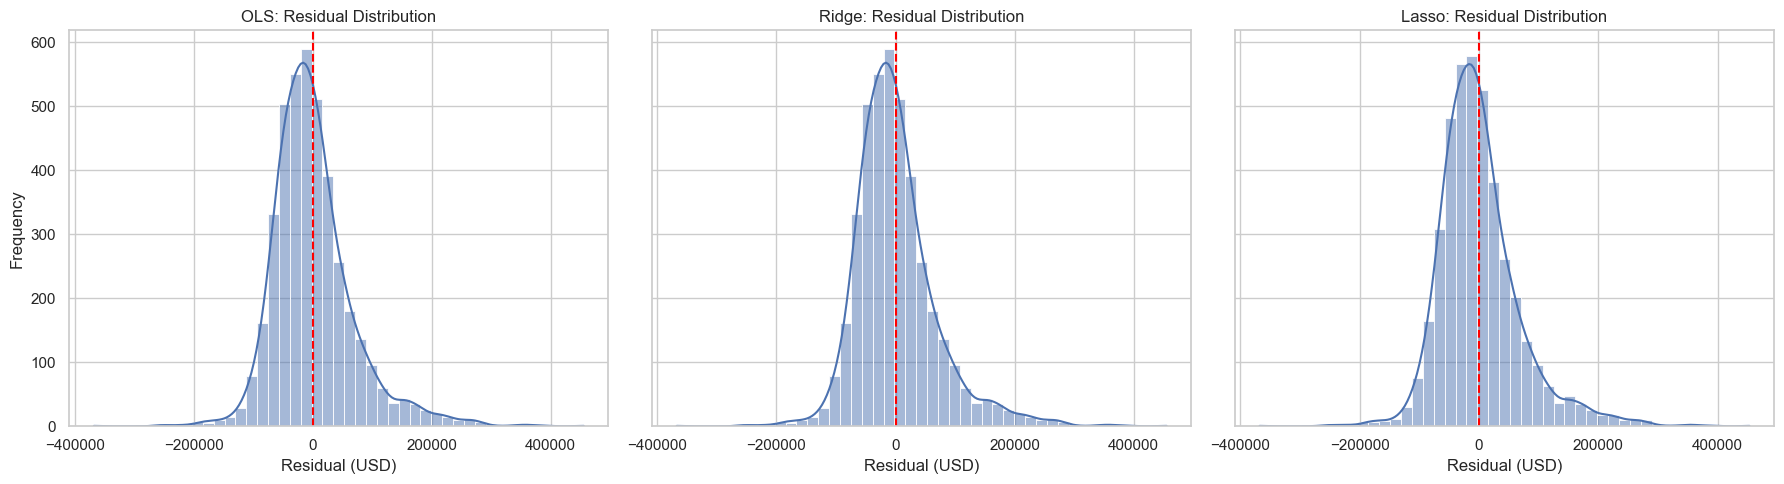

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (model_name, model_residuals) in zip(axes, residuals.items()):
    sns.histplot(model_residuals, bins=45, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{model_name}: Residual Distribution")
    ax.set_xlabel("Residual (USD)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## 18. Residual summary

The following table provides the mean and standard deviation of residuals. A residual mean close to zero is desirable, although the shape and spread of residuals also matter.


In [37]:
residual_summary = pd.DataFrame({
    name: {
        "mean_residual": np.mean(values),
        "std_residual": np.std(values, ddof=1),
        "minimum_residual": np.min(values),
        "maximum_residual": np.max(values)
    }
    for name, values in residuals.items()
}).T

display(residual_summary.style.format("{:,.2f}"))


,mean_residual,std_residual,minimum_residual,maximum_residual
OLS,855.36,"68,601.37","-367,602.56","455,561.79"
Ridge,855.37,"68,601.39","-367,602.79","455,561.10"
Lasso,879.86,"68,739.37","-367,761.88","453,255.76"


## 19. Inspect Lasso coefficients and feature selection

Lasso can shrink some coefficients exactly to zero. We extract the transformed feature names and coefficients to see which variables remain in the selected model.

A non-zero coefficient is not proof of causality or independent importance. Correlated predictors can share or compete for coefficient weight.


In [42]:
lasso_pipeline_fitted = best_lasso.regressor_
lasso_preprocessor = lasso_pipeline_fitted.named_steps["preprocessor"]
lasso_regressor = lasso_pipeline_fitted.named_steps["regressor"]

try:
    transformed_feature_names = lasso_preprocessor.get_feature_names_out()
    coefficient_table = pd.DataFrame({
        "feature": transformed_feature_names,
        "coefficient": lasso_regressor.coef_
    })
    coefficient_table["absolute_coefficient"] = coefficient_table["coefficient"].abs()
    coefficient_table = coefficient_table.sort_values(
        "absolute_coefficient", ascending=False
    )

    display(coefficient_table.head(20))
    nonzero_count = np.count_nonzero(lasso_regressor.coef_)
    zero_count = len(lasso_regressor.coef_) - nonzero_count
    print(f"Non-zero coefficients: {nonzero_count}")
    print(f"Zero coefficients: {zero_count}")
except Exception as error:
    print("Could not extract feature names:", error)


,feature,coefficient,absolute_coefficient
12,numeric__latitude_x_longitude,2.828,2.828
1,numeric__latitude,1.792,1.792
0,numeric__longitude,-1.071,1.071
7,numeric__median_income,0.789,0.789
15,categorical__ocean_proximity_ISLAND,0.732,0.732
5,numeric__population,-0.394,0.394
14,categorical__ocean_proximity_INLAND,-0.321,0.321
6,numeric__households,0.312,0.312
9,numeric__bedrooms_per_room,0.154,0.154
11,numeric__income_x_rooms_per_household,-0.135,0.135


Non-zero coefficients: 17
Zero coefficients: 1


## 20. Optional interactive dashboard

If Plotly is installed, this section creates an interactive chart for the model comparison. Plotly is optional; the static Matplotlib and Seaborn plots above are the required visual outputs.


In [43]:
try:
    import plotly.express as px

    interactive_metrics = metrics_table.reset_index(names="Model")
    fig = px.bar(
        interactive_metrics,
        x="Model", y=["RMSE", "MAE"],
        barmode="group",
        title="Interactive Model Error Comparison (USD)",
        labels={"value": "Error (USD)", "variable": "Metric"}
    )
    fig.show()

    fig_r2 = px.bar(
        interactive_metrics,
        x="Model", y="R2",
        title="Interactive Test R² Comparison",
        labels={"R2": "R²"}
    )
    fig_r2.show()

except ImportError:
    print("Plotly is not installed. Optional installation: python3 -m pip install plotly")


## 21. Optional permutation importance

Permutation importance measures how much a fitted model's score decreases when one input column is randomly shuffled. It is model-agnostic and calculated on the held-out test set here, so treat it as a descriptive diagnostic rather than a causal explanation.

Because the pipeline accepts the original input columns, permutation importance is calculated on the original columns (the engineered variables are generated inside the pipeline).


,feature,importance_mean,importance_std
3,total_rooms,"569,451.254","219,329.051"
4,total_bedrooms,"463,720.880","63,600.101"
7,median_income,"61,393.484",979.962
6,households,"44,844.903","11,440.149"
0,longitude,"26,673.163",497.752
1,latitude,"25,161.356",680.785
5,population,"25,080.326",486.958
8,ocean_proximity,"5,432.926",238.538
2,housing_median_age,"2,592.367",158.896


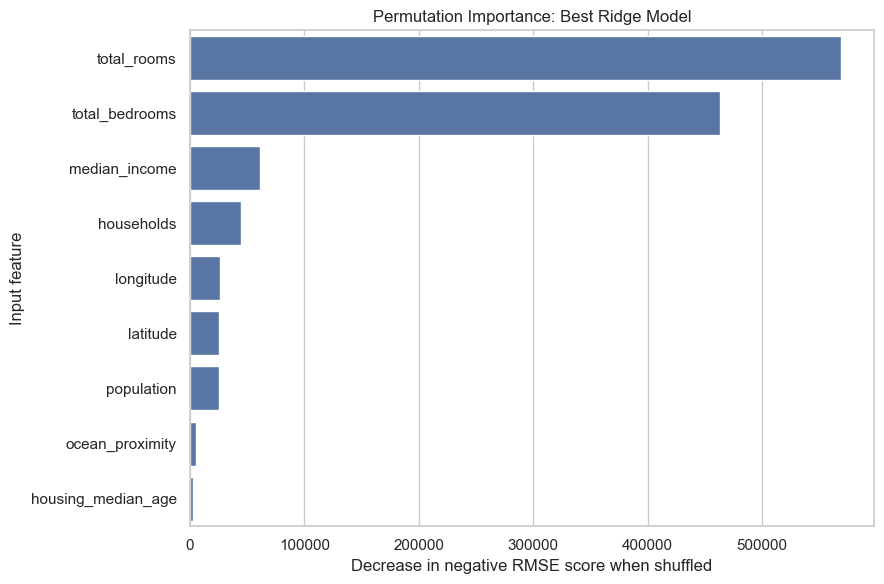

In [44]:
# This can take a little time because the model is evaluated repeatedly.
importance_result = permutation_importance(
    best_ridge, X_test, y_test,
    n_repeats=5,
    random_state=RANDOM_STATE,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_table)

plt.figure(figsize=(9, 6))
sns.barplot(
    data=importance_table.head(12),
    x="importance_mean", y="feature"
)
plt.title("Permutation Importance: Best Ridge Model")
plt.xlabel("Decrease in negative RMSE score when shuffled")
plt.ylabel("Input feature")
plt.tight_layout()
plt.show()


## 22. Final model comparison and project conclusion

The following cell prints the key findings from the computed results. Do not copy example scores from another run: the values below are generated from the actual notebook execution and your dataset.

### Suggested interpretation guide

1. Identify the model with the lowest test RMSE.
2. Check whether that model also has a low MAE and high R².
3. Compare the Ridge and Lasso cross-validation-selected alpha values.
4. Discuss whether regularisation improved upon OLS.
5. Use residual plots to describe systematic errors, spread and possible heteroscedasticity.
6. Mention the dataset's $500,001 target cap as a limitation.

### Limitations

- The dataset represents district-level census summaries, not individual property transactions.
- The target is capped at $500,001 in the source data.
- Linear models may not fully capture complex nonlinear geographic and economic effects.
- Performance on this historical dataset does not guarantee performance on current property markets.
- The random split measures performance on held-out observations from the same dataset; it is not a time-based forecast.


In [47]:
print("FINAL TEST-SET MODEL COMPARISON")
display(metrics_table.style.format({
    "RMSE": "${:,.2f}",
    "MAE": "${:,.2f}",
    "R2": "{:.4f}"
}))

print(f"\nBest model by test RMSE: {best_model_name}")
print(f"Ridge selected alpha: {ridge_search.best_params_['regressor__regressor__alpha']}")
print(f"Lasso selected alpha: {lasso_search.best_params_['regressor__regressor__alpha']}")

print("\nConclusion prompts:")
print("1. Did Ridge or Lasso improve test RMSE compared with OLS?")
print("2. Which model has the strongest combination of RMSE, MAE and R²?")
print("3. What do the residual plots reveal about model errors?")
print("4. Which features appear most useful according to permutation importance?")
print("5. How might the target-value ceiling affect conclusions?")


FINAL TEST-SET MODEL COMPARISON


,RMSE,MAE,R2
OLS,"$68,598.40","$49,442.69",0.6409
Ridge,"$68,598.41","$49,442.70",0.6409
Lasso,"$68,736.68","$49,546.47",0.6394



Best model by test RMSE: OLS
Ridge selected alpha: 0.0001
Lasso selected alpha: 0.0001

Conclusion prompts:
1. Did Ridge or Lasso improve test RMSE compared with OLS?
2. Which model has the strongest combination of RMSE, MAE and R²?
3. What do the residual plots reveal about model errors?
4. Which features appear most useful according to permutation importance?
5. How might the target-value ceiling affect conclusions?


## 23. Save model results and plots

This section saves the model metrics, residual summaries and predictions as CSV files so that the results can be included in the project submission.

The output directory is created automatically.


In [48]:
OUTPUT_DIR = Path("outputs")
PLOTS_DIR = OUTPUT_DIR / "plots"
RESULTS_DIR = OUTPUT_DIR / "model_results"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

metrics_table.to_csv(RESULTS_DIR / "model_metrics.csv")
residual_summary.to_csv(RESULTS_DIR / "residual_summary.csv")

prediction_output = pd.DataFrame({
    "actual_house_value": y_test.to_numpy(),
    "ols_prediction": predictions["OLS"],
    "ridge_prediction": predictions["Ridge"],
    "lasso_prediction": predictions["Lasso"]
})
prediction_output.to_csv(RESULTS_DIR / "test_set_predictions.csv", index=False)

print("Saved:")
print("-", RESULTS_DIR / "model_metrics.csv")
print("-", RESULTS_DIR / "residual_summary.csv")
print("-", RESULTS_DIR / "test_set_predictions.csv")


Saved:
- outputs/model_results/model_metrics.csv
- outputs/model_results/residual_summary.csv
- outputs/model_results/test_set_predictions.csv
